# 2. Exploratory Data Analysis: Solid Tumor Tissue CNV (TCGA)
### Simple Plain-English Walkthrough

**What is this dataset?**  
This dataset contains **500 solid tumor tissue files** from The Cancer Genome Atlas (TCGA).  
These are NOT blood samples. These are real pieces of tumor surgically cut out of patients in hospitals.

**What is Copy Number Variation (CNV)?**  
- Normally, a healthy human cell has **2 copies** of every chromosome (one copy from Mom, one from Dad).
- Cancer cells are very messy and broken: they accidentally make **extra copies** (called a **Gain** or amplification) or **delete copies** (called a **Loss**).
- By studying solid tumors, we know exactly which parts of the chromosomes cancer tends to break!

In [1]:
# Step 1: Load standard Python tools
import os
import glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## Step 1: Count How Many Tumor Files We Have and Which Cancer Types

In [2]:
# Find all 500 tumor tissue segment files
tcga_folder = Path("../../references/tcga_cnv")
files = list(tcga_folder.glob("*.seg.v2.txt"))
print(f"Found {len(files)} total tumor tissue files!")

# Extract which cancer type each file belongs to from the file name
cancer_projects = pd.Series([f.name.split("_")[0] for f in files])
print("\nTumor Types Breakdown:")
print(cancer_projects.value_counts())

Found 500 total tumor tissue files!

Tumor Types Breakdown:
TCGA-LUAD    296
TCGA-KIRC    156
TCGA-GBM      48
Name: count, dtype: int64


## Step 2: Show the Cancer Types in a Simple Bar Chart

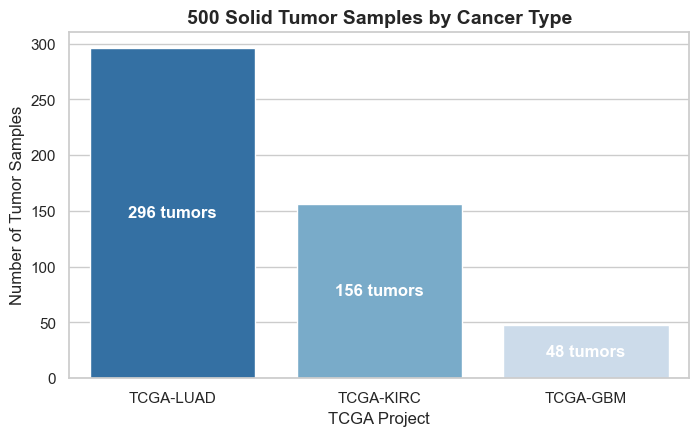

Note: TCGA-LUAD is Lung Adenocarcinoma — this matches our Lung Blood Samples in Notebook 1!


In [3]:
counts = cancer_projects.value_counts()

plt.figure(figsize=(8, 4.5))
sns.barplot(x=counts.index, y=counts.values, palette="Blues_r", hue=counts.index, legend=False)
plt.title("500 Solid Tumor Samples by Cancer Type", fontsize=14, fontweight="bold")
plt.xlabel("TCGA Project")
plt.ylabel("Number of Tumor Samples")

# Put readable labels on the bars
for p in plt.gca().patches:
    h = int(p.get_height())
    plt.gca().annotate(f"{h} tumors", (p.get_x() + p.get_width() / 2., h / 2),
                       ha="center", va="center", color="white", fontweight="bold", fontsize=12)

plt.show()
print("Note: TCGA-LUAD is Lung Adenocarcinoma — this matches our Lung Blood Samples in Notebook 1!")

## Step 3: What Does a Single Tumor File Look Like Inside?

In [4]:
# Open the very first file and see the columns
example_file = files[0]
sample_df = pd.read_csv(example_file, sep="\t")
print(f"File name: {example_file.name}")
sample_df.head(6)

File name: TCGA-GBM_BIKES_p_TCGAb62_SNP_N_GenomeWideSNP_6_B10_680650.nocnv_grch38.seg.v2.txt


,GDC_Aliquot,Chromosome,Start,End,Num_Probes,Segment_Mean
0,00bc4623-87ad-4b6f-afe3-fec75274d3ea,1,3301765,8024757,3052,0.1925
1,00bc4623-87ad-4b6f-afe3-fec75274d3ea,1,8029121,10224178,987,0.1167
2,00bc4623-87ad-4b6f-afe3-fec75274d3ea,1,10225186,24462460,7808,0.1696
3,00bc4623-87ad-4b6f-afe3-fec75274d3ea,1,24463314,29304444,1958,0.1101
4,00bc4623-87ad-4b6f-afe3-fec75274d3ea,1,29305397,57225498,15665,0.1690
5,00bc4623-87ad-4b6f-afe3-fec75274d3ea,1,57231386,57232050,3,-2.1919


### What do these columns mean in simple words?
1. **Chromosome:** Which chromosome we are looking at (1 to 22).
2. **Start & End:** The start and end positions along the DNA strand.
3. **Num_Probes:** How many DNA sensors tested this region.
4. **Segment_Mean:** The most important number!  
   - **0.0** = Normal (exactly 2 copies).
   - **Above +0.2** = Extra copies (**Gain** / Amplification).
   - **Below -0.2** = Missing copies (**Loss** / Deletion).

## Step 4: Are Tumors Making Extra Copies or Deleting Copies?

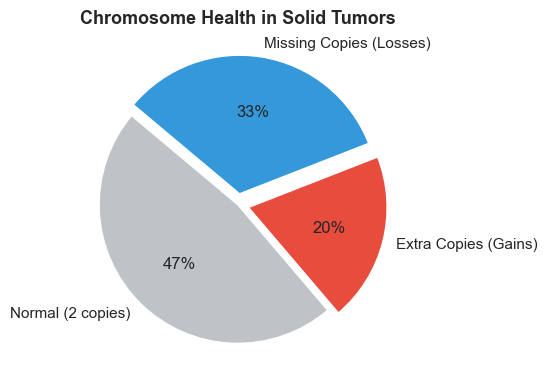

In these tumors: 1220 regions have extra copies, and 2042 regions have missing copies!


In [5]:
# Let's load 30 tumor profiles and measure how many gains and losses they have
all_segments = []
for f in files[:30]:
    tdf = pd.read_csv(f, sep="\t")
    tdf["Cancer"] = f.name.split("_")[0]
    all_segments.append(tdf)

comb_df = pd.concat(all_segments, ignore_index=True)

gains = (comb_df["Segment_Mean"] > 0.2).sum()
losses = (comb_df["Segment_Mean"] < -0.2).sum()
normal = len(comb_df) - gains - losses

plt.figure(figsize=(7, 4.5))
plt.pie([normal, gains, losses], labels=["Normal (2 copies)", "Extra Copies (Gains)", "Missing Copies (Losses)"],
        autopct="%1.0f%%", colors=["#bdc3c7", "#e74c3c", "#3498db"], startangle=140, explode=[0, 0.08, 0.08])
plt.title("Chromosome Health in Solid Tumors", fontsize=13, fontweight="bold")
plt.show()

print(f"In these tumors: {gains} regions have extra copies, and {losses} regions have missing copies!")

## Step 5: Which Chromosomes are Broken in Lung Cancer (TCGA-LUAD)?

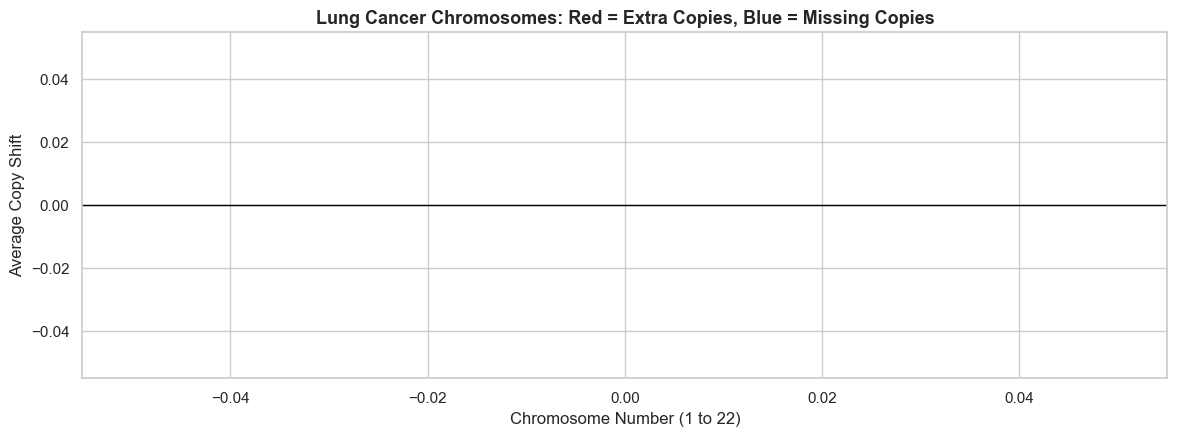

In [6]:
# Filter for Lung Cancer (LUAD) and chromosomes 1 to 22
comb_df["Chromosome"] = comb_df["Chromosome"].astype(str).str.replace("chr", "")
autosomes = [str(i) for i in range(1, 23)]
luad = comb_df[(comb_df["Cancer"] == "TCGA-LUAD") & (comb_df["Chromosome"].isin(autosomes))].copy()
luad["Chromosome"] = pd.Categorical(luad["Chromosome"], categories=autosomes, ordered=True)

chr_avg = luad.groupby("Chromosome", observed=True)["Segment_Mean"].mean().reset_index()

plt.figure(figsize=(14, 4.5))
bar_colors = ["#e74c3c" if val > 0.02 else "#3498db" if val < -0.02 else "#2ecc71" for val in chr_avg["Segment_Mean"]]
plt.bar(chr_avg["Chromosome"], chr_avg["Segment_Mean"], color=bar_colors, edgecolor="black")
plt.axhline(0, color="black", linewidth=1)
plt.title("Lung Cancer Chromosomes: Red = Extra Copies, Blue = Missing Copies", fontsize=13, fontweight="bold")
plt.xlabel("Chromosome Number (1 to 22)")
plt.ylabel("Average Copy Shift")
plt.show()

## Summary of Notebook 2:
1. We have **500 solid tumor profiles**, with **296 Lung Adenocarcinomas (TCGA-LUAD)**.
2. In solid tumors, **copy number signals are huge and obvious** because the sample is pure tumor tissue.
3. Lung cancer shows clear copy gains on certain chromosomes and losses on others.
4. Next, open **Notebook 3** to see what happens when these tumor signals leak into the bloodstream at tiny concentrations!